In [1]:
import pandas as pd

In [175]:
df = pd.read_csv('carprices.csv')
X = df[['Mileage', 'Age(yrs)']]
Y = df['Sell Price($)']
Y

0     18000
1     34000
2     26100
3     40000
4     31500
5     26750
6     32000
7     19300
8     12000
9     22000
10    18700
11    19500
12    26000
13    27500
14    19400
15    35000
16    35500
17    19700
18    12800
19    28200
Name: Sell Price($), dtype: int64

Visualising the multilinear relation between the independent and dependent feature vectors

In [176]:
import matplotlib.pyplot as plt
import numpy as np

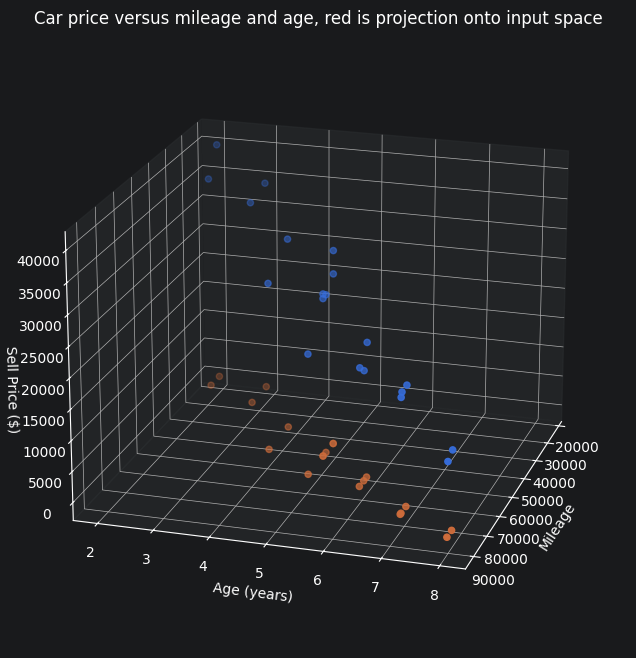

In [177]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')

ax.scatter(
    X['Mileage'],
    X['Age(yrs)'],
    Y
)
ax.scatter(
    X['Mileage'],
    X['Age(yrs)'],
    np.zeros(len(X['Mileage']))
)

ax.set_xlabel('Mileage')
ax.set_ylabel('Age (years)')
ax.set_zlabel('Sell Price ($)')
ax.set_title('Car price versus mileage and age, red is projection onto input space')

ax.view_init(elev=20, azim=17)


plt.show()

In [178]:
from sklearn.model_selection import train_test_split

In [179]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [180]:
from sklearn.linear_model import LinearRegression
clf = LinearRegression()

In [181]:
clf.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [182]:
clf.score(X_test, Y_test)

0.8360253892678233

In [217]:
from math import log10, floor, ceil

m = round(min(X['Mileage']), -int(floor(log10(min(X['Mileage'])))))
M = round(max(X['Mileage']), -int(ceil(log10(min(X['Mileage'])))))

a = round(min(X['Age(yrs)']), -int(floor(log10(min(X['Age(yrs)'])))))
A = round(max(X['Age(yrs)']), -int(ceil(log10(min(X['Age(yrs)'])))))

X1 = np.linspace(m,M,150)
X2 = np.linspace(a,A,150)
X1, X2 = np.meshgrid(X1,X2)

grid = pd.DataFrame({
    'Mileage': X1.ravel(),
    'Age(yrs)': X2.ravel()
})

Z = clf.predict(grid).reshape(X1.shape)


X1_data = X['Mileage']
X2_data = X['Age(yrs)']
X1_data, X2_data = np.meshgrid(X1_data, X2_data)

grid_data = pd.DataFrame({
    'Mileage': X1_data.ravel(),
    'Age(yrs)': X2_data.ravel()
})
Z_pred = clf.predict(grid_data).reshape(X1_data.shape)

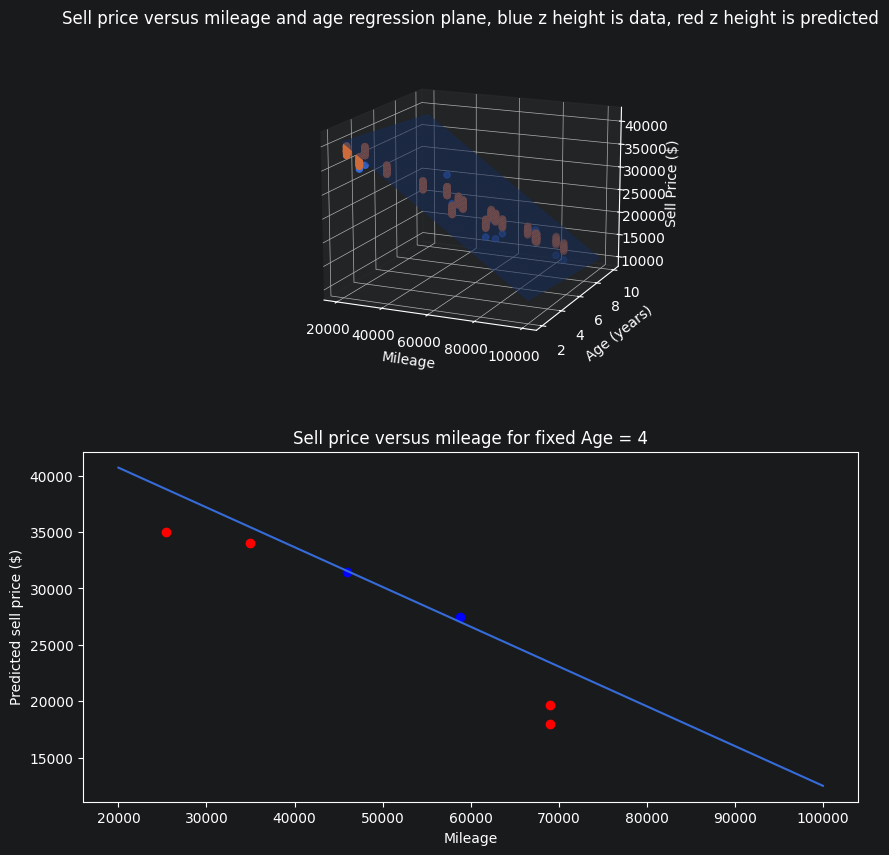

In [227]:


fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(211,projection='3d')

ax.plot_surface(X1, X2, Z, alpha=0.6)

ax.scatter(
    X['Mileage'],
    X['Age(yrs)'],
    Y
)
ax.scatter(
    X['Mileage'],
    X['Age(yrs)'],
    Z_pred
)

ax.set_xlabel('Mileage')
ax.set_ylabel('Age (years)')
ax.set_zlabel('Sell Price ($)')
ax.set_title('Sell price versus mileage and age regression plane, blue z height is data, red z height is predicted')

fixed_age = 4
mask = X['Age(yrs)'] == fixed_age

ax2 = fig.add_subplot(212)
ax2.plot(X1[fixed_age,:], Z[fixed_age,:])
ax2.scatter(X_train.loc[mask, 'Mileage'], Y_train.loc[mask], color='blue')
ax2.scatter(X_test['Mileage'], Y_test, color='red')

ax2.set(xlabel='Mileage', ylabel='Predicted sell price ($)', title=f'Sell price versus mileage for fixed Age = {fixed_age}')


ax.view_init(elev=15, azim=-66)
